# Graphs 2: Shortest paths, trees, flows and matchings

*Learning path: graphs and networks, part 2 of 3.* [Index](README.md) · Previous: [Graphs, degrees and tours](01-graphs-and-tours.ipynb) · Next: [Colorings, orderings and networks](03-colorings-orderings-and-networks.ipynb)

A navigation app finds the fastest route among millions of roads in a fraction of a second. A telecom company lays
cable to connect every town for the least money. An oil company asks how much can flow through its pipelines, and a
manager wants to give every worker a job they can do. These are four of the most useful questions in applied
mathematics, and each has a beautiful algorithm. This lesson shows all four on graphs small enough to check by hand.

**Who this is for.** Students who have done [lesson 1](01-graphs-and-tours.ipynb). No calculus is needed.

**What you will be able to do afterwards:**

1. find shortest paths with Dijkstra's algorithm and breadth-first search;
2. build a minimum spanning tree with Kruskal's algorithm, and count spanning trees;
3. compute a maximum flow and a minimum cut, and explain why they are equal;
4. find a largest matching between two groups.

Plan about 60 minutes. Each section ends with a **Try this**; exercises, hints and answers are at the end.

## 1. Shortest routes: Dijkstra's algorithm

Here are seven Dutch cities with approximate road distances in kilometres between neighbouring ones. Each edge row
has a third column, the **weight**:

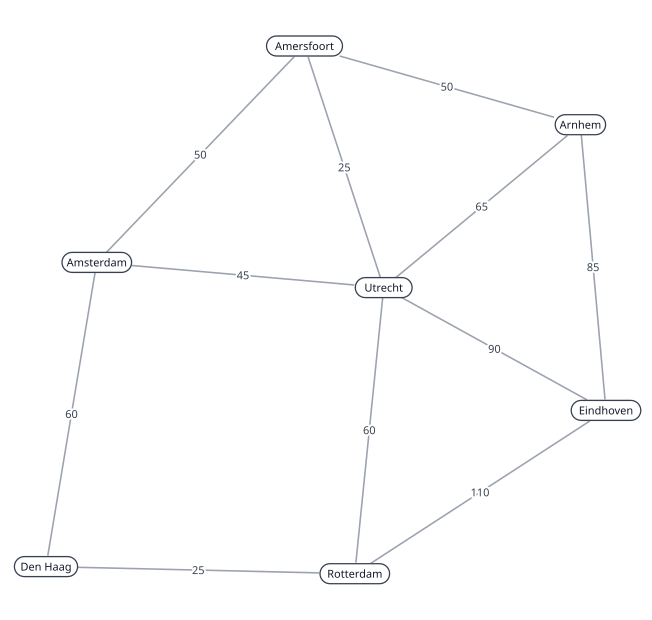

> 7 vertices, 11 edges with weights

In [1]:
R = graph(["Amsterdam" "Utrecht" 45; "Amsterdam" "Den Haag" 60; "Amsterdam" "Amersfoort" 50; "Den Haag" "Rotterdam" 25; "Rotterdam" "Utrecht" 60; "Utrecht" "Amersfoort" 25; "Utrecht" "Arnhem" 65; "Amersfoort" "Arnhem" 50; "Rotterdam" "Eindhoven" 110; "Utrecht" "Eindhoven" 90; "Arnhem" "Eindhoven" 85])

What is the shortest way from Den Haag to Arnhem?

In [2]:
shortest(R, "Den Haag", "Arnhem")
dist(R, "Den Haag", "Arnhem")

{"Den Haag", "Rotterdam", "Utrecht", "Arnhem"}

> total weight 150 along 3 edges (Dijkstra's algorithm)

150

> the total weight of a shortest path from "Den Haag" to "Arnhem"

Edsger Dijkstra found the method in 1956, in about twenty minutes, sitting on a café terrace in Amsterdam. It grows a
set of cities whose distance is **final**:

1. The start has distance 0; every other city has a tentative distance $\infty$.
2. Take the city with the smallest tentative distance that is not final yet, and make it final.
3. For each neighbour, check whether going through this city is shorter than its tentative distance; if so, lower it.
4. Repeat until the destination is final.

Step 2 is safe because all weights are positive: any other route to that city would first have to reach a city that
is at least as far away. Here: Den Haag 0; then Rotterdam 25 and Amsterdam 60; Rotterdam is final and gives Utrecht 85
and Eindhoven 135; Amsterdam is final and gives Amersfoort 110; Utrecht 85 is final and gives Arnhem 150; and so on.

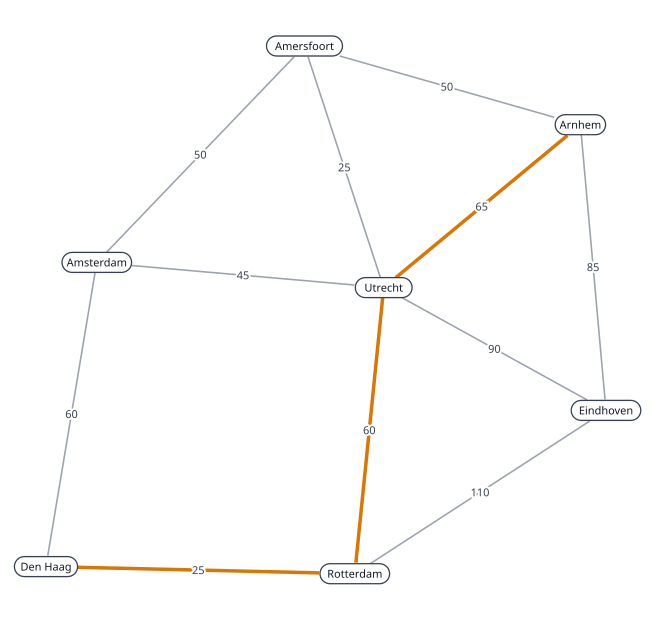

> 3 edges marked in orange

In [3]:
draw(R, shortest(R, "Den Haag", "Arnhem"))

`dist(R)` gives the whole table of distances (rows and columns in the order of `vertices(R)`), the kind printed in
road atlases. The **diameter** is the largest entry, the longest trip you might ever need:

In [4]:
vertices(R)
dist(R)
diameter(R)

{"Amsterdam", "Utrecht", "Den Haag", "Amersfoort", "Rotterdam", "Arnhem", "Eindhoven"}

> 7 vertices

[  0, 45,  60,  50,  85, 100, 135;
  45,  0,  85,  25,  60,  65,  90;
  60, 85,   0, 110,  25, 150, 135;
  50, 25, 110,   0,  85,  50, 115;
  85, 60,  25,  85,   0, 125, 110;
 100, 65, 150,  50, 125,   0,  85;
 135, 90, 135, 115, 110,  85,   0]

> entry (i, j) is the distance from vertex i to vertex j; inf means no path (Floyd–Warshall)

150

> the largest distance between two vertices, e.g. from "Den Haag" to "Arnhem"

**Try this.** A new motorway is built from Den Haag to Utrecht, 55 km. Add it (copy the definition of `R` and add a
row) and find the new shortest route to Arnhem. Which entries of `dist` change?

## 2. Without weights: breadth-first search

When every edge counts the same, as on a grid of streets or in a maze, the shortest path is the one with the fewest
edges. Then Dijkstra's method becomes **breadth-first search**: visit the start, then all its neighbours, then all of
theirs, and so on. The order in which `bfs` visits the vertices is ordered by distance:

{1, 2, 7, 3, 8, 13, 4, 9, 14, 19, 5, 10, 15, 20, 6, 11, 16, 21, 12, 17, 22, 18, 23, 24}

> breadth-first: the start, then all its neighbours, then their new neighbours, and so on (smaller vertices first); the order is by distance from the start

8

> the number of edges of a shortest path from 1 to 24

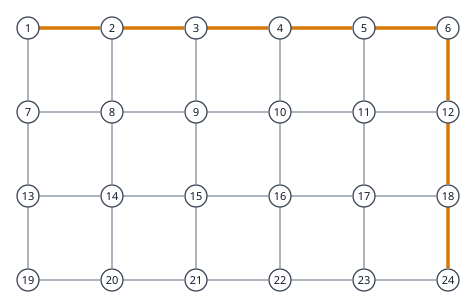

> 8 edges marked in orange

In [5]:
G = grid(4, 6);
bfs(G, 1)
dist(G, 1, 24)
draw(G, shortest(G, 1, 24))

From one corner of a $4 \times 6$ grid to the opposite one takes $3 + 5 = 8$ steps, and there are many shortest
paths; Galileo shows one. In social networks diameters are surprisingly small, the "six degrees of separation". The
Petersen graph is an extreme case: 10 vertices of degree 3, and every vertex is at most 2 steps from every other.

In [6]:
diameter(petersen())

2

> the largest distance between two vertices, e.g. from 1 to 3

**Try this.** What is `dist(grid(m, n), 1, m*n)` in general? Check with two grids of your choice.

## 3. Connecting everything cheaply: spanning trees

Suppose cables can be laid along the roads of section 1, and every city must be connected, directly or indirectly.
A set of edges that connects all vertices without any cycle is a **spanning tree**; with $n$ vertices it always has
$n - 1$ edges (a cycle would contain a redundant edge, and fewer edges cannot connect everything). Which spanning
tree is cheapest?

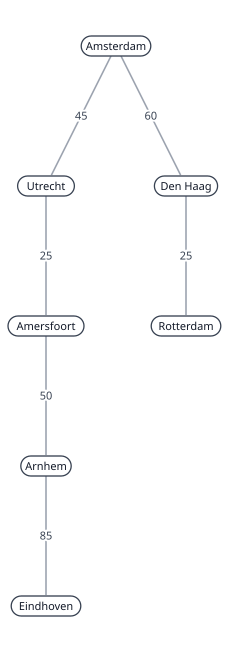

> 6 edges, total weight 290; Kruskal's algorithm: take the lightest edges first, skipping any that would close a cycle

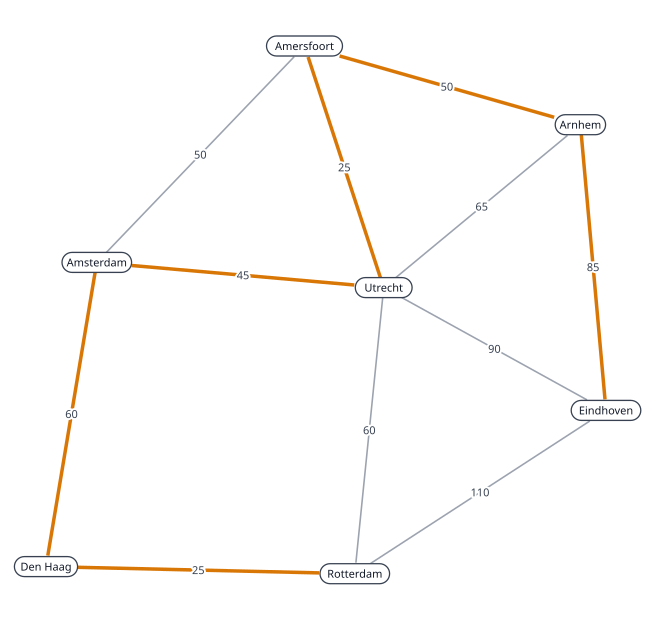

> 6 edges marked in orange

In [7]:
T = mst(R)
draw(R, T)

Joseph Kruskal's algorithm (1956) is greedy: sort the edges from cheapest to dearest, and take each one unless it
would close a cycle with the edges already taken. Here: Den Haag-Rotterdam 25, Utrecht-Amersfoort 25,
Amsterdam-Utrecht 45, then Amsterdam-Amersfoort 50 is skipped (it closes a triangle), Amersfoort-Arnhem 50 is taken,
and so on. The total is 290 km. Greed is not usually optimal, but here it is: whenever the vertices are split into two
groups, the cheapest edge between the groups belongs to some minimum spanning tree.

How many spanning trees are there to choose from? Gustav Kirchhoff showed in 1847, while studying electrical
networks, that the number is a determinant: delete one row and the same column from the Laplacian matrix
$L = D - A$ of lesson 1, and take the determinant.

In [8]:
spanningtrees(R)
spanningtrees(complete(5))

176

> the number of different spanning trees (Kirchhoff's matrix-tree theorem: any cofactor of the Laplacian)

125

> the number of different spanning trees (Kirchhoff's matrix-tree theorem: any cofactor of the Laplacian)

So Kruskal found the best of 176 trees without looking at most of them. For the complete graph on $n$ vertices the
count is $n^{n-2}$ (Cayley's formula): $5^3 = 125$.

**Try this.** Check Cayley's formula for $n = 3, 4, 6$. How many spanning trees does `cycle(n)` have, and why?

## 4. Maximum flow and minimum cut

Now the edges are one-way pipes, and the weight of each is its **capacity**: how much can flow through it per hour.
Water enters at the source `s` and leaves at the sink `t`. How much can the network carry?

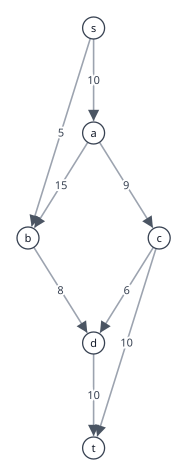

> 6 vertices, 8 directed edges with weights

15

> flow on the edges: "s" → "a": 10, "s" → "b": 5, "a" → "b": 1, "a" → "c": 9, "b" → "d": 6, "c" → "t": 9, "d" → "t": 6. A minimum cut, ["s", "a", 10; "s", "b", 5], has the same total capacity (max-flow min-cut theorem). Edmonds–Karp: push flow along shortest paths with room left until none is left.

In [9]:
F = digraph(["s" "a" 10; "s" "b" 5; "a" "b" 15; "a" "c" 9; "b" "d" 8; "c" "d" 6; "c" "t" 10; "d" "t" 10])
maxflow(F, "s", "t")

The note lists how much flows through each pipe. At every vertex except `s` and `t`, what flows in flows out. The
method (Ford and Fulkerson, 1956; Edmonds and Karp, 1972) repeatedly finds a path from `s` to `t` that still has room,
pushes as much as it can along it, and remembers that flow pushed along a pipe may later be pushed back.

Why can no more than 15 flow? Look at the pipes leaving `s`: together they carry at most $10 + 5 = 15$. Any set of
pipes whose removal disconnects `t` from `s` is a **cut**, and no flow can exceed the capacity of any cut:

In [10]:
mincut(F, "s", "t")

["s", "a", 10;
 "s", "b",  5]

> removing these 2 edges separates "s" from "t"; their capacities add up to 15, the maximum flow (max-flow min-cut theorem)

The **max-flow min-cut theorem** says the largest flow equals the smallest cut. This is a kind of certificate: the
flow shows 15 is possible, the cut shows more is impossible. During the Cold War, the US Air Force studied the Soviet
rail network this way: the minimum cut was the cheapest set of lines to bomb to stop the flow of supplies.

**Try this.** Increase the capacity of `s` to `b` from 5 to 20. What is the new maximum flow, and where is the new
bottleneck?

## 5. Matching workers to jobs

Five people can each do some of four jobs. An edge means "can do". A **matching** pairs people with jobs so that
nobody gets two jobs and no job gets two people:

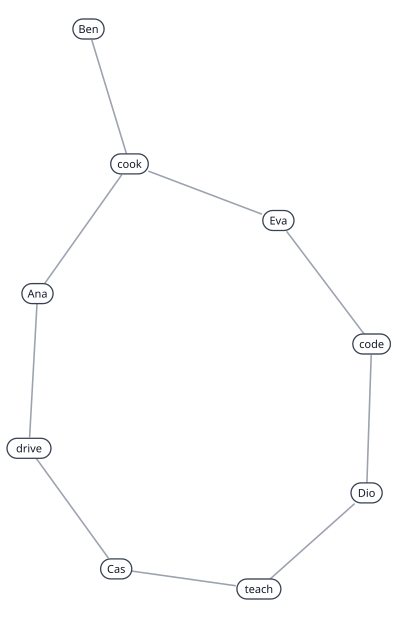

> 9 vertices, 9 edges

["Ana", "cook";
 "Cas", "drive";
 "Dio", "teach";
 "Eva", "code"]

> 4 pairs, the most possible (Edmonds' blossom algorithm)

In [11]:
J = graph(["Ana" "cook"; "Ana" "drive"; "Ben" "cook"; "Cas" "drive"; "Cas" "teach"; "Dio" "teach"; "Dio" "code"; "Eva" "code"; "Eva" "cook"])
matching(J)

All four jobs are filled, and one person is left over. Matching is a flow problem in disguise: add a source joined to
every person and a sink joined to every job, all with capacity 1; a maximum flow is a maximum matching. Philip Hall's
**marriage theorem** (1935) says when every person can be matched: exactly when every group of $k$ people can do at
least $k$ different jobs between them.

Matchings also make sense when the graph is not split in two sides, for example pairing room-mates. Then odd cycles
make it harder, and Jack Edmonds' **blossom algorithm** (1965), which Galileo uses, shrinks them to single points:

[1,  2;
 3,  4;
 5, 10;
 6,  8;
 7,  9]

> 5 pairs, the most possible (Edmonds' blossom algorithm); a perfect matching: every vertex is paired

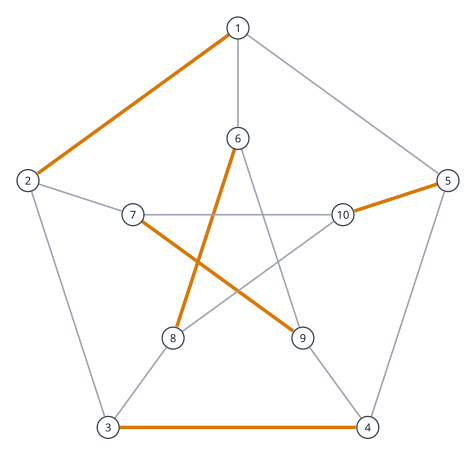

> 5 edges marked in orange

In [12]:
matching(petersen())
draw(petersen(), matching(petersen()))

The Petersen graph has a **perfect matching**: all 10 vertices in 5 pairs.

**Try this.** Remove Eva's edge to `code`: can all four jobs still be filled? Then remove Dio's edge to `code` too,
and use Hall's theorem (applied to the jobs) to explain the answer.

## Summary

* Dijkstra's algorithm makes the closest unfinished vertex final, again and again; with equal weights it is
  breadth-first search.
* A spanning tree connects $n$ vertices with $n - 1$ edges; Kruskal's greedy method finds the cheapest. Kirchhoff's
  determinant counts them all, $n^{n-2}$ for a complete graph.
* The maximum flow equals the minimum cut; each certifies the other.
* A maximum matching pairs as many vertices as possible; Hall's theorem says when everyone can be matched.

Next: [colorings, orderings and networks](03-colorings-orderings-and-networks.ipynb).

## Exercises

1. **Dijkstra by hand.** Run Dijkstra's algorithm from Amsterdam on the city graph, writing the tentative distances
   after each step. Check with the first row of `dist(R)`.
2. **Negative weights.** In `digraph([1 2 4; 1 3 2; 3 2 -3])` one road pays you to use it. What does
   `dist(D, 1, 2)` give, and why would Dijkstra's rule of section 1 go wrong here?
3. **Second-best tree.** Remove the edge Arnhem-Eindhoven from `R` and compute `mst` again. How much more does the
   cable network cost?
4. **Two cuts.** Find a cut in `F` of capacity 19 by hand, and check that it is not smaller than the flow.
5. **Hall's theorem.** In `complete(3, 5)` (three people, five jobs, everyone can do everything) how large is a
   maximum matching? And in `complete(5, 3)`?

## Hints and answers

* **Section 1, Try this.** Den Haag, Utrecht, Arnhem: $55 + 65 = 120$ km instead of 150. Distances from Den Haag
  to Utrecht, Amersfoort, Arnhem and Eindhoven get shorter.
* **Section 2, Try this.** $(m - 1) + (n - 1)$: every step moves one row or one column.
* **Section 3, Try this.** 3, 16 and 1296 trees. `cycle(n)` has $n$: remove any one of its $n$ edges.
* **Section 4, Try this.** 17. The new bottleneck is in the middle: the pipes `a` to `c` (9) and `b` to `d` (8)
  are the minimum cut.
* **Section 5, Try this.** Yes the first time: Ana drives, Ben cooks, Cas teaches, Dio codes, and Eva is left over.
  The second time no: the job `code` has nobody who can do it, so the group {code} of one job has zero people, and
  only 3 jobs can be filled.
* **Exercise 1.** Final in the order Amsterdam 0, Utrecht 45, Amersfoort 50, Den Haag 60, Rotterdam 85, Arnhem 100,
  Eindhoven 135.
* **Exercise 2.** $-1$, along 1, 3, 2. Dijkstra would make vertex 2 final too early (at distance 4); Galileo switches
  to the Bellman-Ford algorithm when it sees a negative weight.
* **Exercise 3.** The tree must use Utrecht-Eindhoven 90 instead of 85: 5 km more.
* **Exercise 4.** Put `s`, `a`, `b`, `d` on one side: the pipes `a` to `c` (9) and `d` to `t` (10) cross, 19 in all,
  which is more than the flow of 15, as it must be.
* **Exercise 5.** 3 in both: only three people (or three jobs) to go round.

## Sources

1. E. W. Dijkstra, "A note on two problems in connexion with graphs", *Numerische Mathematik* 1 (1959) 269–271.
2. J. B. Kruskal, "On the shortest spanning subtree of a graph and the traveling salesman problem", *Proceedings of
   the AMS* 7 (1956) 48–50.
3. L. R. Ford and D. R. Fulkerson, "Maximal flow through a network", *Canadian Journal of Mathematics* 8 (1956)
   399–404; A. Schrijver, "On the history of the transportation and maximum flow problems", *Mathematical
   Programming* 91 (2002) 437–445 (the rail network study).
4. J. Edmonds, "Paths, trees, and flowers", *Canadian Journal of Mathematics* 17 (1965) 449–467.
5. P. Hall, "On representatives of subsets", *Journal of the London Mathematical Society* 10 (1935) 26–30.
6. J. Kleinberg and É. Tardos, *Algorithm Design*, Pearson (2005), chapters 4 and 7.